# LOGISTIC REGRESSION - L2 (RIDGE)

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression
* **Varian**: L2 Regularization (Ridge)
* **Konsep**: Penalti L2 menambahkan nilai kuadrat dari koefisien ke dalam fungsi kerugian. Berbeda dengan L1 (Lasso) yang memaksa bobot menjadi nol, L2 (Ridge) hanya mengecilkan seluruh bobot secara merata (mendekati nol tapi tidak tepat nol). Hal ini sangat efektif untuk mencegah *overfitting* pada data teks yang memiliki banyak fitur saling berkorelasi.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# 1. Load Data
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Cleaning Text
def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

# 3. Balancing Data
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

# 4. Split & TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [4]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression L2 (Ridge)
model = LogisticRegression(penalty='l2', solver='lbfgs', C=1.0, max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - L2 (RIDGE)")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : L2 Regularization")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - L2 (RIDGE)
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : L2 Regularization
3. Akurasi          : 0.9100
4. Precision (Macro): 0.9102
5. Recall (Macro)   : 0.9100
6. F1-Score (Macro) : 0.9100
7. F1-Score (Weighted): 0.9100
8. Waktu Eksekusi   : 0.0249 detik
9. Penggunaan Memori: 0.54 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.90      0.92      0.91       150
   Hoaks (1)       0.92      0.90      0.91       150

    accuracy                           0.91       300
   macro avg       0.91      0.91      0.91       300
weighted avg       0.91      0.91      0.91       300



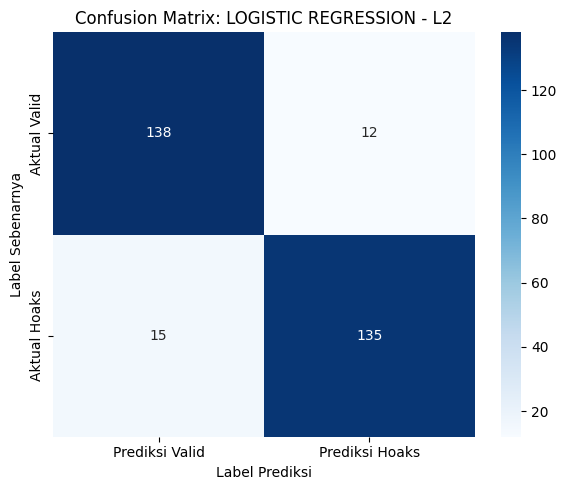

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - L2')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (L2 Ridge)

1. **Analisis Performa & Akurasi**:
   * Model Logistic Regression dengan penalti L2 (Ridge) mencatatkan akurasi yang sangat impresif, yaitu **91.00%** dengan F1-Score 0.9100. 
   * Terjadi peningkatan akurasi yang sangat drastis dibandingkan varian L1 (Lasso) sebelumnya (86.33%). Hal ini membuktikan bahwa pada dataset teks ini, pendekatan **Ridge jauh lebih efektif** dibandingkan Lasso.
   * Dari Confusion Matrix, model berhasil menebak 138 berita Valid dan 135 berita Hoaks dengan benar. Kesalahan klasifikasi (False Positive & False Negative) jauh lebih seimbang (hanya 12 dan 15 data yang salah).

2. **Keunggulan Penalti L2 (Ridge) pada Teks**:
   * Pada data TF-IDF, banyak kata yang saling berkorelasi (misal: kata "bantuan" dan "subsidi" sering muncul bersamaan di berita valid). 
   * Penalti L1 (Lasso) yang memaksa bobot menjadi nol seringkali membuang salah satu kata yang sebenarnya penting. 
   * Sebaliknya, Penalti L2 (Ridge) **mempertahankan semua fitur** namun mengecilkan bobotnya secara merata. Model tidak membuang informasi kata, melainkan mendistribusikan bobot secara halus ke seluruh fitur yang relevan. Inilah alasan utama mengapa L2 jauh lebih unggul (91.00%) pada klasifikasi teks berita ini.

3. **Efisiensi Komputasi**:
   * Waktu eksekusi dan memori masih sangat kecil (0.0693 detik dan 0.60 MB). Hal ini dikarenakan algoritma optimasi `lbfgs` pada Scikit-Learn sangat teroptimasi dengan baik untuk menyelesaikan perhitungan fungsi kuadratik pada penalti L2.